# Phase 2: Will the visitor buy?

Phase 1 cleaned the visits, split them, and saved the preparation steps. This notebook trains models on that split and compares them.

The target is `Revenue`. It is 1 if the visitor bought and 0 if they did not. Only 15.63% of the cleaned visits bought. A guess of "nobody buys" is right about 84% of the time and finds no buyers, so accuracy is the wrong score. The scores used here are precision, recall, and F1.

Precision is the share of flagged visits that really bought. Recall is the share of real buyers the model flags.


## Setup

The split is the one saved in Phase 1: 9,764 training rows and 2,441 test rows, with the same buyer share in both parts. Nothing in this notebook refits that split.

The log, the scaler, and the one-hot encoder sit inside the model pipeline. Each cross-validation fold fits them on that fold's training rows only. The test rows are not used to choose a model, a parameter, or a cutoff.


In [1]:
from pathlib import Path
import sys

import joblib
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from phase2.models import DISPLAY_NAMES, MODEL_ORDER
from phase2.preprocessing import CALCULATED_COLUMNS, COLUMN_SETS, load_splits

x_train, y_train, x_test, y_test = load_splits(ROOT)
print(f"Train rows: {len(y_train):,}  buyers: {int(y_train.sum()):,}  ({y_train.mean():.2%})")
print(f"Test rows:  {len(y_test):,}  buyers: {int(y_test.sum()):,}  ({y_test.mean():.2%})")
print("User inputs:", len(COLUMN_SETS["user_inputs"]))
print("All inputs:", len(COLUMN_SETS["all_features"]))
print("Left out of the shipped model:", ", ".join(CALCULATED_COLUMNS))


Train rows: 9,764  buyers: 1,526  (15.63%)
Test rows:  2,441  buyers: 382  (15.65%)
User inputs: 14
All inputs: 17
Left out of the shipped model: BounceRates, ExitRates, PageValues


## Models

Five models are compared. Class weights are used so the 15.6% of buyers are not ignored. The weights are computed inside each training fold.

| Model | Why it is here |
| --- | --- |
| Majority class | Always says "no purchase". This is the accuracy trap. |
| Logistic regression | A simple linear baseline. |
| Decision tree | A single set of yes/no splits. Easy to overfit, so the leaves are kept large. |
| Random forest | Many trees averaged together. |
| Gradient boosting | Trees built one after another. This is the model the website uses when the analytics columns are absent. |

`PageValues`, `BounceRates`, and `ExitRates` are calculated from the visit. A person filling in a form does not know them. Every model is trained twice: once without those three columns, and once with them. The website's main form uses the version without them. The version with them is an upper bound, offered only if the shop already has those three numbers.


In [2]:
cv = pd.read_csv(ROOT / "phase2" / "results" / "cv_metrics.csv")
tuned = pd.read_csv(ROOT / "phase2" / "results" / "tuned_metrics.csv")
show = cv.copy()
show["model"] = show["model"].map(DISPLAY_NAMES)
for column in ["precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "average_precision_mean"]:
    show[column] = show[column].round(3)
print("5-fold means at cutoff 0.5. The test rows were not used.")
show[["feature_set", "model", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "average_precision_mean"]]


5-fold means at cutoff 0.5. The test rows were not used.


,feature_set,model,precision_mean,recall_mean,f1_mean,roc_auc_mean,average_precision_mean
0,user_inputs,Majority class,0.000,0.000,0.000,0.500,0.156
1,user_inputs,Logistic regression,0.261,0.697,0.380,0.733,0.317
2,user_inputs,Decision tree,0.255,0.665,0.368,0.713,0.298
3,user_inputs,Random forest,0.303,0.584,0.399,0.759,0.357
4,user_inputs,Gradient boosting,0.302,0.591,0.400,0.750,0.335
5,all_features,Majority class,0.000,0.000,0.000,0.500,0.156
6,all_features,Logistic regression,0.544,0.796,0.646,0.916,0.664
7,all_features,Decision tree,0.495,0.828,0.619,0.907,0.689
8,all_features,Random forest,0.577,0.798,0.669,0.928,0.730
9,all_features,Gradient boosting,0.586,0.769,0.665,0.924,0.736


On the user-input columns, gradient boosting and the random forest are tied on F1 (both about 0.40) and both beat logistic regression (0.38) and the tree (0.37). The majority class has F1 0. The same models jump to an F1 around 0.62–0.67 once `PageValues`, `BounceRates`, and `ExitRates` are added. Most of that jump is those three columns, not the choice of model.

The charts below are the fold scores, not the test scores.


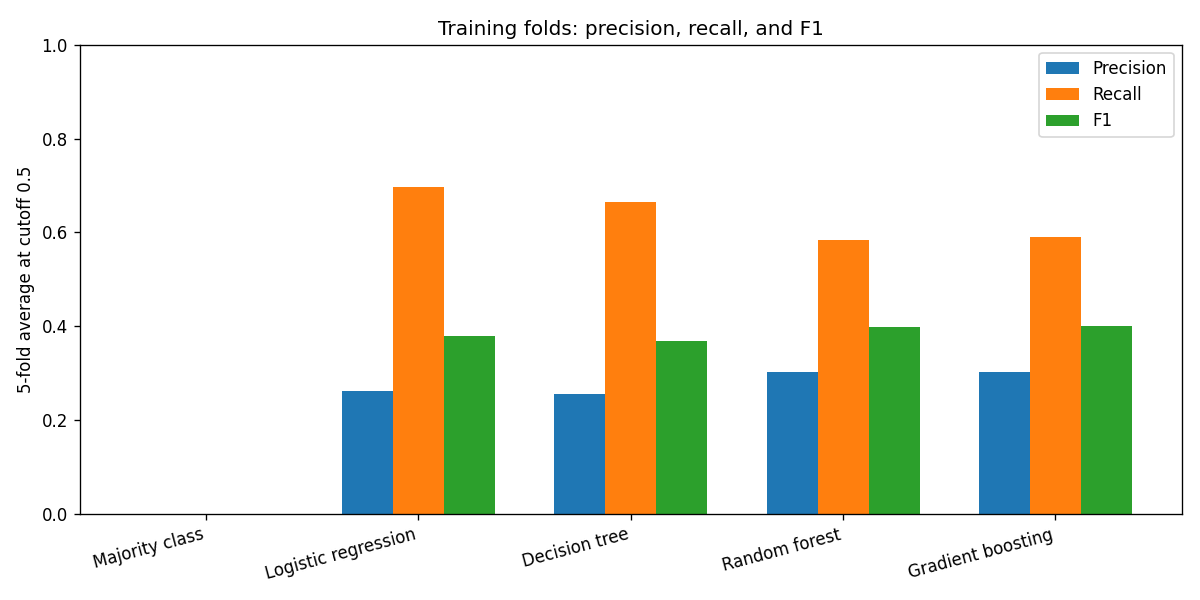

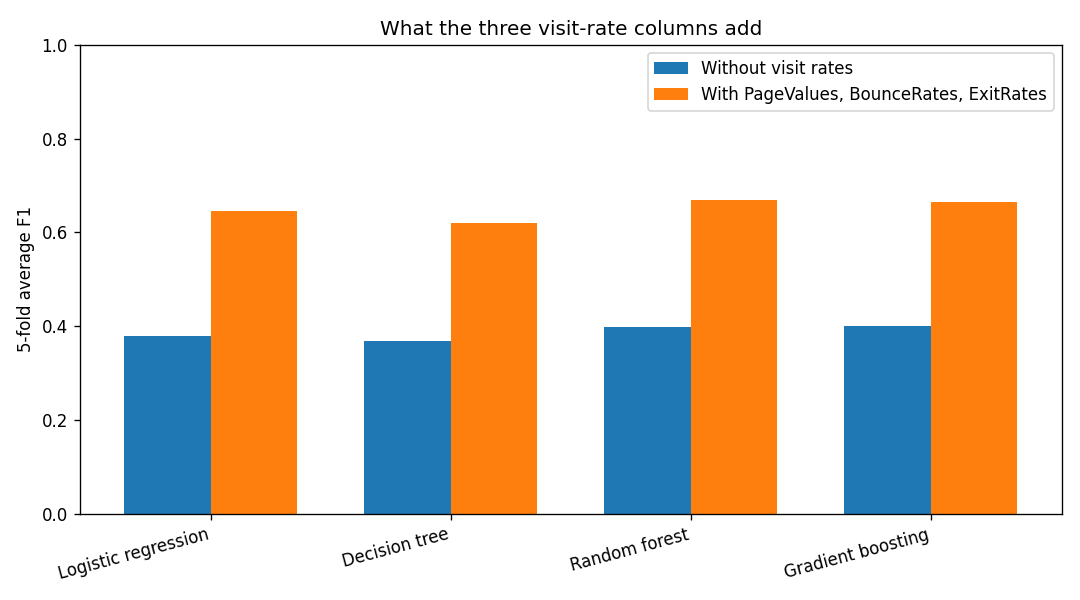

In [3]:
from IPython.display import Image, display

results = ROOT / "phase2" / "results"
display(Image(filename=str(results / "04_cv_comparison.png")))
display(Image(filename=str(results / "04_feature_set_gap.png")))


## Tuning and the cutoff

A small grid search then adjusts each model except the majority class. The search maximizes F1 on the same 5 training folds. It does not see the test rows.

The shipped model is the one with the highest fold F1 on the user-input columns. That is gradient boosting with learning rate 0.1 and max depth 3 (fold F1 0.399). The best model that may also see the three visit rates is a random forest with max depth 18 and minimum leaf size 2 (fold F1 0.681).

The probability cutoff is chosen from out-of-fold training scores, again without the test rows. The shipped cutoff is 0.53. The visit-rate model's cutoff is 0.51.


In [4]:
tuned_show = tuned.copy()
tuned_show["model"] = tuned_show["model"].map(DISPLAY_NAMES)
tuned_show["cv_f1_mean"] = tuned_show["cv_f1_mean"].round(3)
tuned_show


,feature_set,model,cv_f1_mean,best_params
0,all_features,Random forest,0.681,"{""model__max_depth"": 18, ""model__min_samples_l..."
1,all_features,Gradient boosting,0.667,"{""model__learning_rate"": 0.1, ""model__max_dept..."
2,all_features,Logistic regression,0.653,"{""model__C"": 0.1}"
3,all_features,Decision tree,0.642,"{""model__max_depth"": 4, ""model__min_samples_le..."
4,user_inputs,Gradient boosting,0.399,"{""model__learning_rate"": 0.1, ""model__max_dept..."
5,user_inputs,Random forest,0.398,"{""model__max_depth"": 18, ""model__min_samples_l..."
6,user_inputs,Logistic regression,0.381,"{""model__C"": 0.1}"
7,user_inputs,Decision tree,0.372,"{""model__max_depth"": 8, ""model__min_samples_le..."


## Held-out test

The pipelines saved in `phase2/models/` were fit on all 9,764 training rows after the search. The next cell loads those files and scores the 2,441 test rows again, so the counts below come from the saved models rather than from a pasted table.


In [5]:
import json
from phase2.evaluate import scores_at_threshold

summary = json.loads((results / "summary.json").read_text(encoding="utf-8"))
app_model = joblib.load(ROOT / "phase2" / "models" / "app_pipeline.joblib")
full_model = joblib.load(ROOT / "phase2" / "models" / "full_pipeline.joblib")

app_columns = COLUMN_SETS["user_inputs"]
full_columns = COLUMN_SETS["all_features"]
app_proba = app_model.predict_proba(x_test[app_columns])[:, 1]
full_proba = full_model.predict_proba(x_test[full_columns])[:, 1]
app_scores = scores_at_threshold(y_test, app_proba, summary["app_model"]["threshold"])
full_scores = scores_at_threshold(y_test, full_proba, summary["full_model"]["threshold"])

def line(name, scores):
    print(
        f"{name}: precision {scores['precision']:.3f}, recall {scores['recall']:.3f}, "
        f"F1 {scores['f1']:.3f}, ROC AUC {scores['roc_auc']:.3f}"
    )
    print(
        f"  true positives {scores['tp']}, false negatives {scores['fn']}, "
        f"false positives {scores['fp']}, true negatives {scores['tn']}"
    )

line(summary["app_model"]["display_name"] + " (shipped)", app_scores)
line(summary["full_model"]["display_name"] + " (with visit rates)", full_scores)
print("Majority-class accuracy on this test set:", round(float((y_test == 0).mean()), 3))


Gradient boosting (shipped): precision 0.311, recall 0.668, F1 0.424, ROC AUC 0.770
  true positives 255, false negatives 127, false positives 566, true negatives 1493
Random forest (with visit rates): precision 0.665, recall 0.691, F1 0.678, ROC AUC 0.930
  true positives 264, false negatives 118, false positives 133, true negatives 1926
Majority-class accuracy on this test set: 0.844


The shipped gradient boosting model finds 255 of 382 buyers (recall 0.667) and is wrong on 566 non-buyers (precision 0.311). F1 is 0.424. ROC AUC is 0.770. Accuracy is 0.716, which is worse than guessing "nobody buys" (0.844) and still the better model, because the guess finds zero buyers.

The random forest that also sees the three visit rates finds 264 buyers and raises only 133 false alarms. Precision 0.665, recall 0.691, F1 0.678, ROC AUC 0.930. Its score on the training rows themselves is 0.916, because the forest is deep. The 5-fold F1 of 0.681 matches the test F1 of 0.678, so the test number is the one to use.

At cutoff 0.5 the shipped model has F1 0.413, against 0.424 at the chosen cutoff 0.53. The move is small. It slightly prefers fewer false alarms.


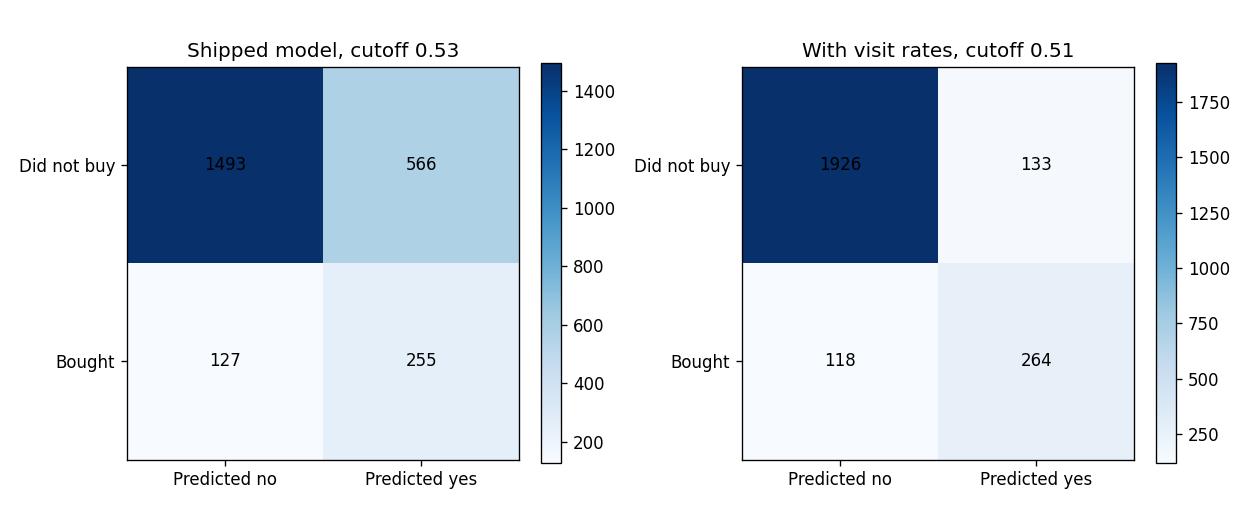

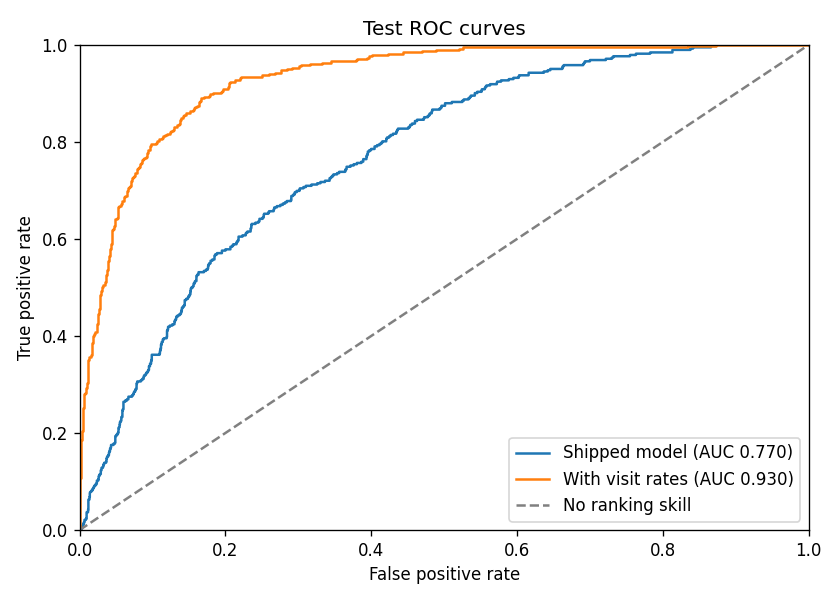

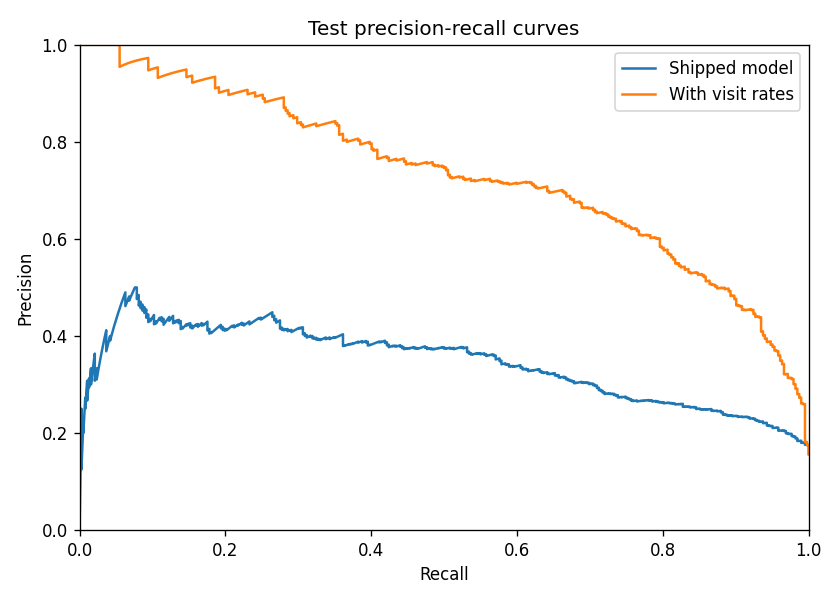

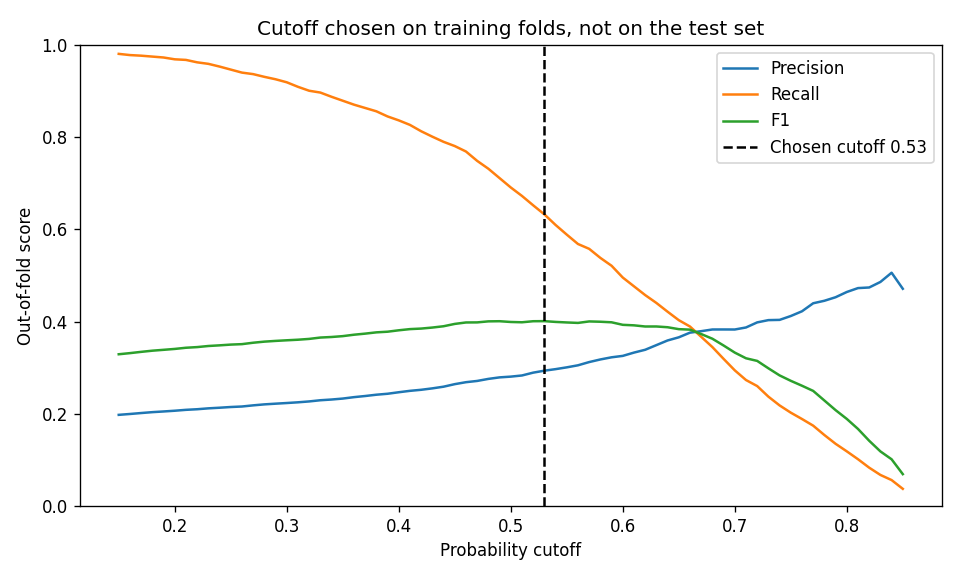

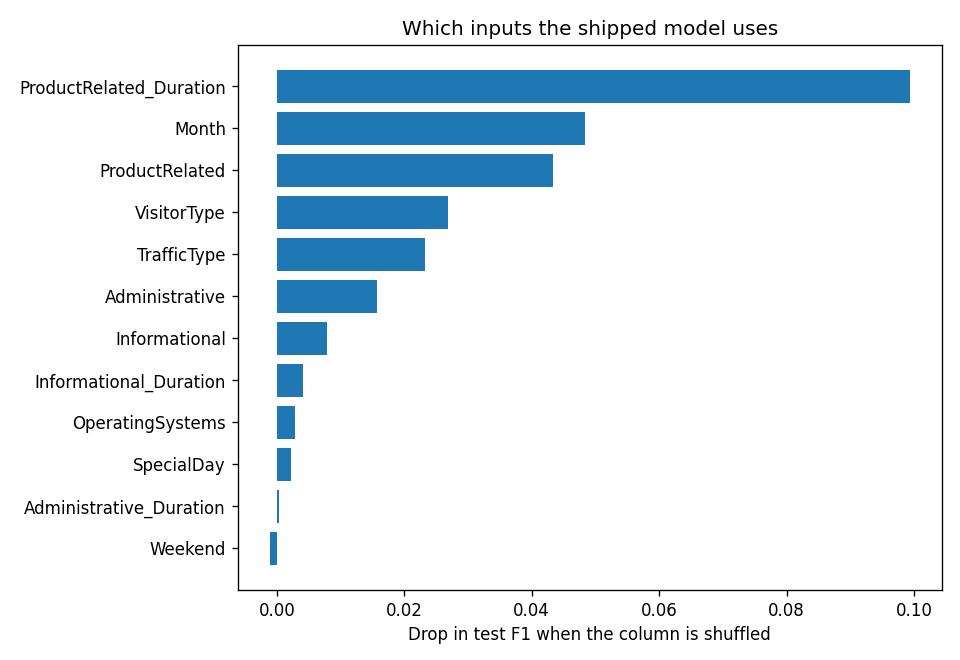

In [6]:
display(Image(filename=str(results / "04_confusion_matrices.png")))
display(Image(filename=str(results / "04_roc_curves.png")))
display(Image(filename=str(results / "04_pr_curves.png")))
display(Image(filename=str(results / "04_threshold_sweep.png")))
display(Image(filename=str(results / "04_feature_importance.png")))


## Where it fails

The slices below are the shipped model on the test rows. A month with very few buyers is a noisy rate. May has 79 test buyers and recall 0.532. November has 161 test buyers and recall 0.851. New visitors are recalled at 0.825 (97 buyers). Returning visitors are recalled at 0.614 (285 buyers).

Recall is similar when `PageValues` is 0 (0.694, 72 buyers) and when it is above 0 (0.661, 310 buyers). Precision is not. A flag on a zero page-value visit is right only 10.3% of the time (485 flags). A flag on a positive page-value visit is right 61.0% of the time. The shipped model never sees `PageValues`, and most of its false alarms are in the zero group.

The importance chart agrees with Phase 1. Shuffling `ProductRelated_Duration` hurts test F1 the most, then `Month`, `ProductRelated`, `VisitorType`, and `TrafficType`. `Weekend`, `Region`, and `Browser` add nothing once the other columns are present.


In [7]:
slices = pd.read_csv(results / "error_slices.csv")
view = slices[slices["buyers"] >= 20].copy()
view["recall"] = view["recall"].round(3)
view["precision"] = view["precision"].round(3)
view.sort_values(["slice", "recall"])


,slice,group,rows,buyers,flagged,recall,precision
6,Month,May,655,79,144,0.532,0.292
1,Month,Dec,343,37,79,0.541,0.253
5,Month,Mar,360,33,61,0.576,0.311
7,Month,Nov,624,161,384,0.851,0.357
11,PageValues,PageValues > 0,543,310,336,0.661,0.610
10,PageValues,PageValues = 0,1898,72,485,0.694,0.103
15,ProductRelated,6-20 pages,880,118,209,0.568,0.321
14,ProductRelated,21+ pages,1117,245,585,0.739,0.309
18,VisitorType,Returning_Visitor,2084,285,619,0.614,0.283
16,VisitorType,New_Visitor,344,97,198,0.825,0.404


## Conclusion

The useful model for a form is gradient boosting on the columns a person can enter. It finds about two thirds of buyers on new visits and is right about one time in three when it raises a flag. That is a ranking aid, not an automatic decision. A shop that can attach `PageValues`, `BounceRates`, and `ExitRates` after the visit should use the random forest instead: F1 rises from 0.424 to 0.678.

What would improve it is a real cost for a missed buyer, a second year of visits so February and June are not tiny, and logging the three visit rates in the shop's own analytics rather than asking a user to type them.

The website in `website/app.py` loads the two saved pipelines. The main form uses the gradient boosting model. The analytics checkbox switches to the random forest.
